# 02. NV2: Phân nhóm hành vi chiếm dụng trạm sạc (NV2) — Khải

## Mục tiêu nghiên cứu (NV2)
Nghiên cứu các kiểu hành vi kết nối và chiếm dụng cổng sạc sau khi xe đã được nạp đầy:
1. **3.2.1. Xây dựng không gian đặc trưng hành vi chiếm dụng trạm sạc**:
   - Kế thừa và phát triển lý thuyết từ **Jonas et al. (2023)** (*Energies*) và **Bayram et al. (2023)** (*IEEE Access*).
   - Thiết lập vector đặc trưng 4 chiều: Thời gian sạc tích cực ($T_{charging}$), Thời gian chiếm dụng nhàn rỗi ($T_{idle}$), Tỷ lệ nhàn rỗi ($Idle\ Ratio$), và Điện năng tiêu thụ ($E$).
   - Khảo sát phân bố, độ lệch và chuẩn hóa Z-score (*StandardScaler*).
2. **3.2.2. Lựa chọn thuật toán phân cụm: So sánh thực nghiệm giữa K-Means và DBSCAN**:
   - So sánh thực nghiệm đa chiều (*Empirical Benchmarking*): Silhouette Score, Davies-Bouldin Index, Calinski-Harabasz Index, WCSS / Inertia, độ phức tạp tính toán, tỷ lệ nhiễu.
   - Khảo sát hạn chế của DBSCAN đối với bài toán mật độ không đồng nhất (*Varying Density Dilemma*) và hiệu ứng chuỗi liên kết (*Chaining Effect*).
   - Lựa chọn mô hình K-Means với $k=4$ tối ưu, huấn luyện trên toàn bộ 259.356 phiên sạc hợp lệ, định danh 4 hồ sơ hành vi và đánh giá sự dịch chuyển cấu trúc trước/sau cú sốc chính sách giá 01/08/2017.

In [1]:
import sys
from pathlib import Path
import time
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

# Thiết lập đường dẫn thư mục gốc
sys.path.append(str(Path.cwd().parent if Path.cwd().name == 'notebooks' else Path.cwd()))
from src.config import SESSIONS_FEATURES_PARQUET, FIGURES_DIR
from src.visualization import set_plotting_style

set_plotting_style()

# 1. Đọc dữ liệu đặc trưng đã làm sạch từ NV1
df = pd.read_parquet(SESSIONS_FEATURES_PARQUET)
valid = df[df['is_valid_session']].copy()
print(f"Tổng số phiên sạc hợp lệ đưa vào phân tích NV2: {len(valid):,} phiên")

Tổng số phiên sạc hợp lệ đưa vào phân tích NV2: 259,356 phiên


---  
## 3.2.1. Xây dựng không gian đặc trưng hành vi chiếm dụng trạm sạc

Theo khung lý thuyết của **Jonas et al. (2023)** và **Bayram et al. (2023)**, một phiên sạc gồm 3 thành phần cốt lõi:
- Tổng thời gian kết nối: $T_{total} = t_{departure} - t_{arrival}$
- Thời gian sạc tích cực: $T_{charging} = t_{charging-end} - t_{arrival}$
- Thời gian chiếm dụng nhàn rỗi (Overstay / Idle time): $T_{idle} = T_{total} - T_{charging}$
- Tỷ lệ chiếm dụng nhàn rỗi: $Idle\ Ratio = \frac{T_{idle}}{T_{total}} = 1 - \frac{T_{charging}}{T_{total}}$
- Điện năng tiêu thụ: $E$ (kWh)

Vector đặc trưng lõi: $\mathbf{x} = [T_{charging}, T_{idle}, Idle\ Ratio, E]^T \in \mathbb{R}^4$.

=== BẢNG THỐNG KÊ MÔ TẢ KHÔNG GIAN ĐẶC TRƯNG HÀNH VI (N = 259.356) ===


,mean,std,min,25%,median,75%,max
charging_time_hours,1.999,1.381,0.003,1.040,1.816,2.697,22.932
idle_time_hours,0.488,1.479,0.000,0.004,0.007,0.355,112.547
idle_ratio,0.116,0.197,0.000,0.002,0.009,0.151,0.999
Energy (kWh),8.542,7.179,0.010,3.784,6.868,11.457,97.360
total_duration_hours,2.487,2.213,0.017,1.171,2.089,3.090,114.539


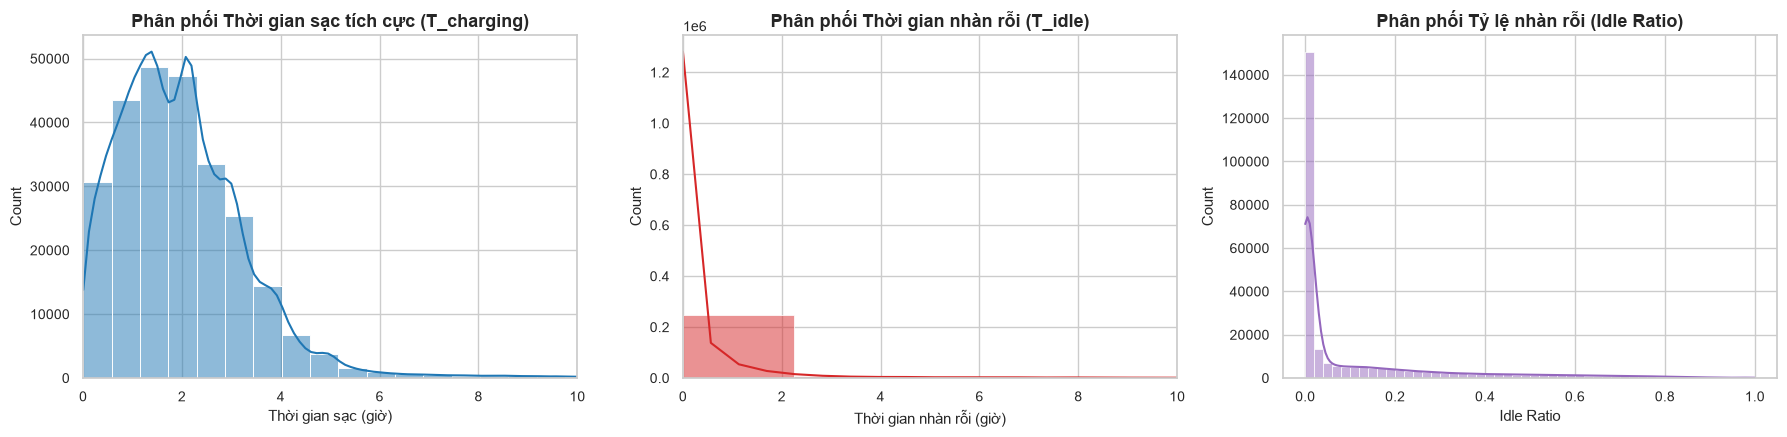

In [2]:
features = ['charging_time_hours', 'idle_time_hours', 'idle_ratio', 'Energy (kWh)']
print("=== BẢNG THỐNG KÊ MÔ TẢ KHÔNG GIAN ĐẶC TRƯNG HÀNH VI (N = 259.356) ===")
desc = valid[features + ['total_duration_hours']].describe().T
desc['median'] = valid[features + ['total_duration_hours']].median()
display(desc[['mean', 'std', 'min', '25%', 'median', '75%', 'max']].round(3))

# Trực quan hóa phân phối của các đặc trưng chiếm dụng
fig, axes = plt.subplots(1, 3, figsize=(18, 4.5))

sns.histplot(valid['charging_time_hours'], bins=40, ax=axes[0], color='#1f77b4', kde=True)
axes[0].set_title('Phân phối Thời gian sạc tích cực (T_charging)', fontweight='bold')
axes[0].set_xlabel('Thời gian sạc (giờ)')
axes[0].set_xlim(0, 10)

sns.histplot(valid['idle_time_hours'], bins=50, ax=axes[1], color='#d62728', kde=True)
axes[1].set_title('Phân phối Thời gian nhàn rỗi (T_idle)', fontweight='bold')
axes[1].set_xlabel('Thời gian nhàn rỗi (giờ)')
axes[1].set_xlim(0, 10)

sns.histplot(valid['idle_ratio'], bins=50, ax=axes[2], color='#9467bd', kde=True)
axes[2].set_title('Phân phối Tỷ lệ nhàn rỗi (Idle Ratio)', fontweight='bold')
axes[2].set_xlabel('Idle Ratio')

plt.tight_layout()
plt.show()

---  
## 3.2.2. Lựa chọn thuật toán phân cụm: So sánh thực nghiệm giữa K-Means và DBSCAN

### Chuẩn hóa đặc trưng và thiết kế tập mẫu đại diện ($N = 20.000$)
Do độ phức tạp của DBSCAN là $O(N^2)$ (đòi hỏi tính khoảng $67,2$ tỷ khoảng cách cặp điểm trên $259.356$ phiên), ta tiến hành rút mẫu phân tầng đại diện $N = 20.000$ phiên để đối sánh thực nghiệm công bằng giữa **K-Means** và **DBSCAN**.

In [3]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans, DBSCAN
from sklearn.metrics import silhouette_score, davies_bouldin_score, calinski_harabasz_score

X = valid[features].dropna()

# Rút mẫu đại diện
np.random.seed(42)
sample_idx = np.random.choice(len(X), size=20000, replace=False)
X_sample = X.iloc[sample_idx].copy()

# Chuẩn hóa Z-score
scaler = StandardScaler()
X_scaled = scaler.fit_transform(X_sample)
print(f"Kích thước tập mẫu thực nghiệm: {X_scaled.shape}")

Kích thước tập mẫu thực nghiệm: (20000, 4)


### 1. Thực nghiệm mô hình K-Means ($k = 2 \dots 7$)

In [4]:
km_results = []
k_range = range(2, 8)

for k in k_range:
    t0 = time.time()
    km = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = km.fit_predict(X_scaled)
    t1 = time.time()
    
    sil = silhouette_score(X_scaled, labels)
    db = davies_bouldin_score(X_scaled, labels)
    ch = calinski_harabasz_score(X_scaled, labels)
    
    km_results.append({
        'k': k,
        'Inertia (WCSS)': km.inertia_,
        'Silhouette Score': sil,
        'Davies-Bouldin': db,
        'Calinski-Harabasz': ch,
        'Execution Time (s)': t1 - t0
    })

df_km = pd.DataFrame(km_results)
print("=== KẾT QUẢ ĐỐI SÁNH THỰC NGHIỆM K-MEANS ===")
display(df_km.round(4))

=== KẾT QUẢ ĐỐI SÁNH THỰC NGHIỆM K-MEANS ===


,k,Inertia (WCSS),Silhouette Score,Davies-Bouldin,Calinski-Harabasz,Execution Time (s)
0,2,56288.1593,0.5619,1.0203,8424.3202,0.4654
1,3,38638.2385,0.4352,0.8908,10703.2731,0.1677
2,4,29245.2730,0.4547,0.7908,11567.6078,0.1101
3,5,21423.7642,0.4455,0.7454,13667.4550,0.2273
4,6,18343.8076,0.3804,0.8352,13440.7227,0.2033
5,7,16161.7763,0.3888,0.8418,13161.9377,0.1729


### 2. Thực nghiệm mô hình DBSCAN theo lưới tham số ($\epsilon \in [0.2, 1.0], MinPts \in [10, 50]$)

In [5]:
db_results = []
for eps in [0.2, 0.3, 0.5, 0.7, 1.0]:
    for min_samples in [10, 30, 50]:
        t0 = time.time()
        db = DBSCAN(eps=eps, min_samples=min_samples)
        labels = db.fit_predict(X_scaled)
        t1 = time.time()
        
        n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
        noise_ratio = np.sum(labels == -1) / len(labels)
        
        non_noise_mask = labels != -1
        if n_clusters > 1 and np.sum(non_noise_mask) > n_clusters:
            sil = silhouette_score(X_scaled[non_noise_mask], labels[non_noise_mask])
            db_score = davies_bouldin_score(X_scaled[non_noise_mask], labels[non_noise_mask])
            ch = calinski_harabasz_score(X_scaled[non_noise_mask], labels[non_noise_mask])
        else:
            sil, db_score, ch = np.nan, np.nan, np.nan
            
        db_results.append({
            'eps': eps,
            'min_samples': min_samples,
            'n_clusters': n_clusters,
            'noise_ratio (%)': round(noise_ratio * 100, 2),
            'Silhouette': sil,
            'Davies-Bouldin': db_score,
            'Calinski-Harabasz': ch,
            'Execution Time (s)': t1 - t0
        })

df_db = pd.DataFrame(db_results)
print("=== KẾT QUẢ ĐỐI SÁNH THỰC NGHIỆM DBSCAN ===")
display(df_db.round(4))

print("Nhận xét: Khi eps >= 0.3 và min_samples >= 30, DBSCAN bị hiệu ứng chuỗi (chaining effect) gom toàn bộ vào duy nhất 1 siêu cụm, làm mất khả năng phân tách hành vi!")

=== KẾT QUẢ ĐỐI SÁNH THỰC NGHIỆM DBSCAN ===


,eps,min_samples,n_clusters,noise_ratio (%),Silhouette,Davies-Bouldin,Calinski-Harabasz,Execution Time (s)
0,0.2,10,7,8.28,0.1714,0.5026,95.0666,1.1130
1,0.2,30,6,18.10,-0.0752,0.8466,89.5600,0.4462
2,0.2,50,2,23.17,0.0528,1.1463,93.3467,0.5220
3,0.3,10,4,4.56,0.5805,0.4375,398.9063,0.6838
4,0.3,30,1,8.54,NaN,NaN,NaN,0.6269
5,0.3,50,1,11.58,NaN,NaN,NaN,0.6171
6,0.5,10,3,1.85,0.6196,0.3080,144.9364,0.9951
7,0.5,30,1,4.64,NaN,NaN,NaN,0.9641
8,0.5,50,1,5.46,NaN,NaN,NaN,0.9625
9,0.7,10,2,0.85,0.7605,0.2048,245.0883,1.3790


Nhận xét: Khi eps >= 0.3 và min_samples >= 30, DBSCAN bị hiệu ứng chuỗi (chaining effect) gom toàn bộ vào duy nhất 1 siêu cụm, làm mất khả năng phân tách hành vi!


### 3. Trực quan hóa đối sánh K-Means và DBSCAN

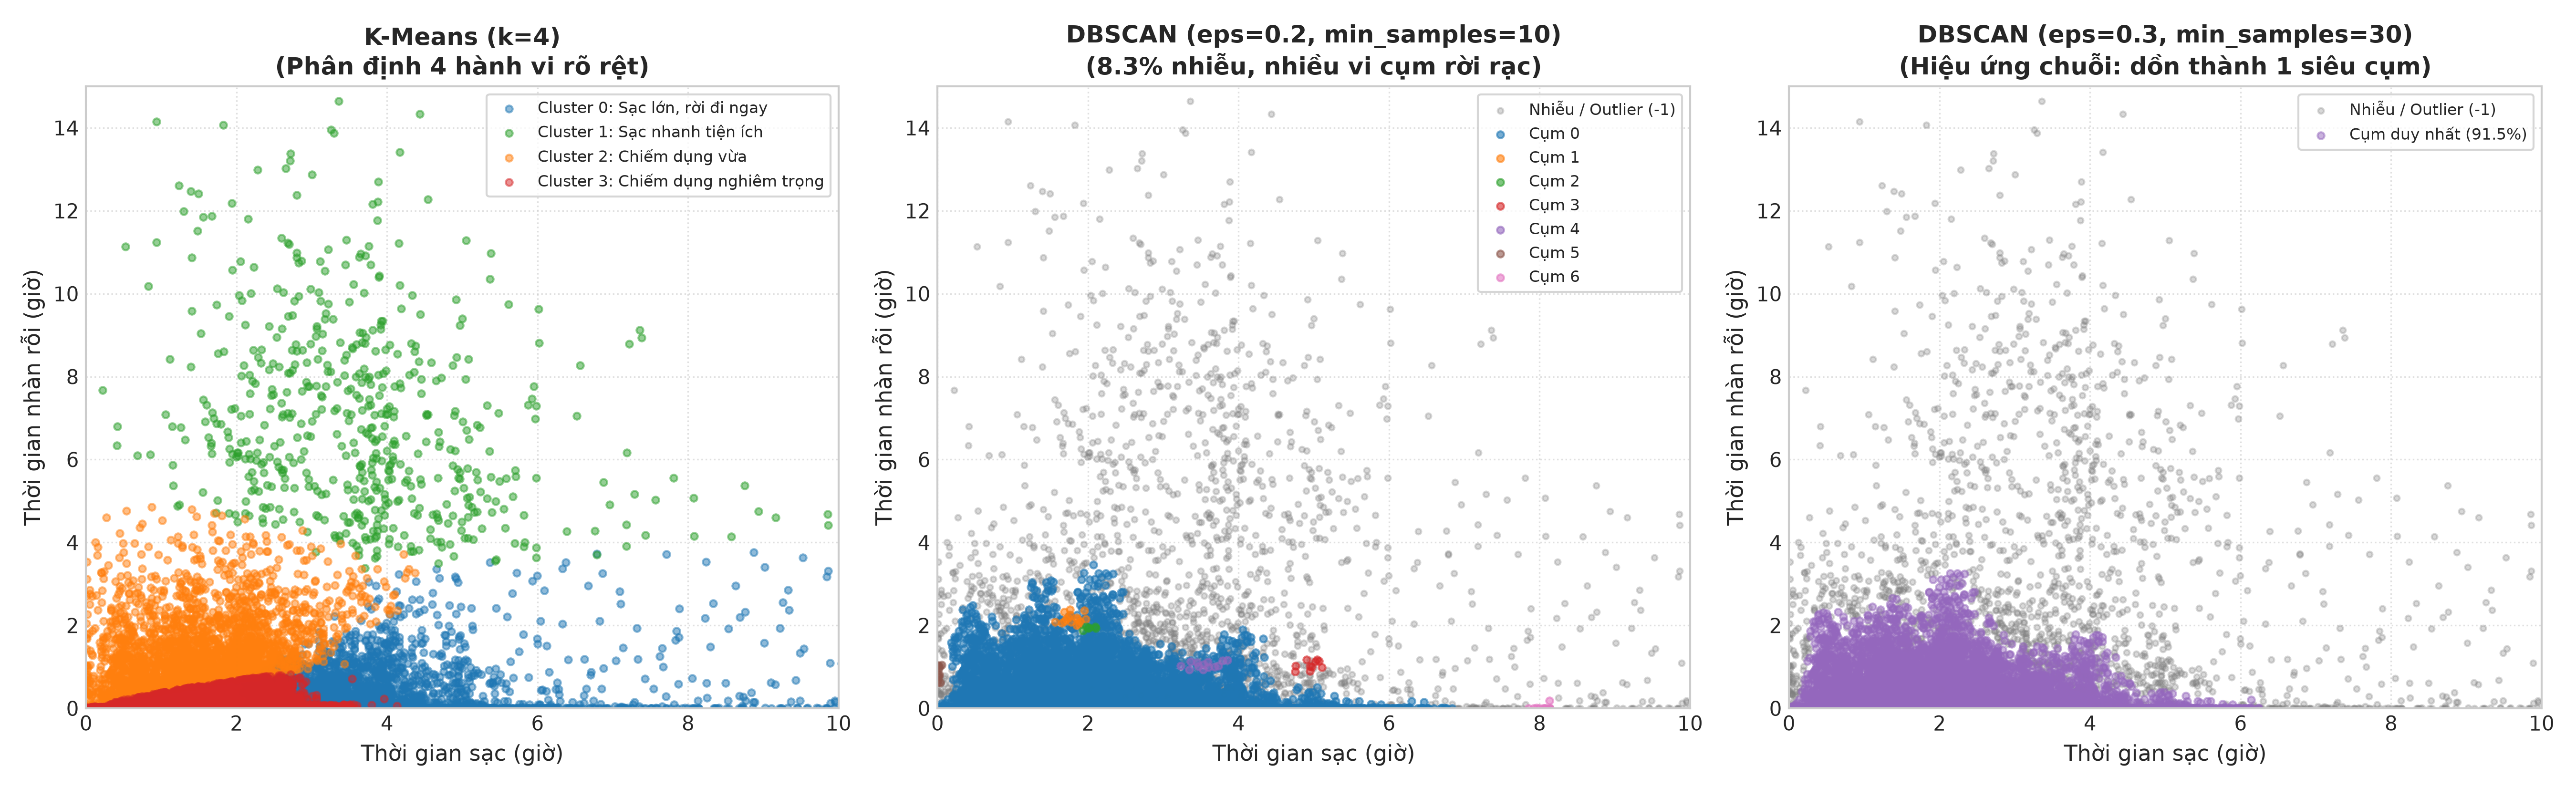

In [6]:
# Hiển thị đồ thị đối sánh trực quan đã xuất
from IPython.display import Image
Image(filename='../reports/figures/clustering_comparison_kmeans_dbscan.png')

---  
## Huấn luyện mô hình chuẩn K-Means ($k=4$) trên toàn bộ 259.356 phiên sạc hợp lệ

Sau khi đối sánh thực nghiệm, **K-Means ($k=4$)** được lựa chọn làm giải pháp tối ưu. Tiến hành huấn luyện trên toàn bộ tập dữ liệu để định danh hồ sơ hành vi người dùng (*User Behavioral Profiles*).

In [7]:
# Huấn luyện trên toàn bộ tập dữ liệu
X_all = valid[features].dropna()
scaler_all = StandardScaler()
X_all_scaled = scaler_all.fit_transform(X_all)

km_final = KMeans(n_clusters=4, random_state=42, n_init=10)
valid['cluster'] = km_final.fit_predict(X_all_scaled)

# Đặt tên và định danh 4 hồ sơ cụm
cluster_names_map = {
    0: 'Cụm 0: Sạc dung lượng lớn, rời đi ngay',
    1: 'Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu',
    2: 'Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)',
    3: 'Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qua đêm'
}
valid['cluster_label'] = valid['cluster'].map(cluster_names_map)

profile = valid.groupby('cluster_label')[features + ['total_duration_hours']].agg(['mean', 'median']).round(2)
profile['session_count'] = valid['cluster_label'].value_counts()
profile['percentage (%)'] = (valid['cluster_label'].value_counts(normalize=True) * 100).round(2)

print("=== HỒ SƠ 4 NHÓM HÀNH VI CHIẾM DỤNG (K-MEANS k=4, N=259.356) ===")
display(profile)

=== HỒ SƠ 4 NHÓM HÀNH VI CHIẾM DỤNG (K-MEANS k=4, N=259.356) ===


charging_time_hours         \
                                                                  mean median   
cluster_label                                                                   
Cụm 0: Sạc dung lượng lớn, rời đi ngay                            3.52   3.16   
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu                   1.35   1.34   
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)                 1.47   1.43   
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...                3.70   3.67   

                                                   idle_time_hours         \
                                                              mean median   
cluster_label                                                               
Cụm 0: Sạc dung lượng lớn, rời đi ngay                        0.24   0.01   
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu               0.07   0.01   
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)             1.39   1.16   
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...            7.45   6.69   

                                                   idle_ratio         \
                                                         mean median   
cluster_label                                                          
Cụm 0: Sạc dung lượng lớn, rời đi ngay                   0.05   0.00   
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu          0.04   0.01   
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)        0.48   0.45   
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...       0.66   0.66   

                                                   Energy (kWh)         \
                                                           mean median   
cluster_label                                                            
Cụm 0: Sạc dung lượng lớn, rời đi ngay                    16.36  14.34   
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu            5.36   5.31   
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)          5.39   5.17   
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...        15.95  13.09   

                                                   total_duration_hours  \
                                                                   mean   
cluster_label                                                             
Cụm 0: Sạc dung lượng lớn, rời đi ngay                             3.75   
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu                    1.42   
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)                  2.86   
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...                11.14   

                                                          session_count  \
                                                   median                 
cluster_label                                                             
Cụm 0: Sạc dung lượng lớn, rời đi ngay               3.32         67981   
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu      1.38        150913   
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)    2.81         33195   
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...  10.50          7267   

                                                   percentage (%)  
                                                                   
cluster_label                                                      
Cụm 0: Sạc dung lượng lớn, rời đi ngay                      26.21  
Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu             58.19  
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h)           12.80  
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qu...           2.80

### Đánh giá sự dịch chuyển cơ cấu các cụm hành vi trước và sau chính sách giá 01/08/2017
Cú sốc chính sách ngày 01/08/2017 áp dụng giá sạc \$0.23/kWh và phí phạt đỗ xe nhàn rỗi \$2/giờ sau 20 phút ân hạn.

=== SỰ DỊCH CHUYỂN CƠ CẤU HÀNH VI TRƯỚC VÀ SAU CHÍNH SÁCH GIÁ ===


is_post_policy,Sau chính sách (Áp phí sạc & phạt nhàn rỗi),Trước chính sách (Miễn phí),Chênh lệch (%)
cluster_label,,,
"Cụm 0: Sạc dung lượng lớn, rời đi ngay",26.67,25.77,-0.91
"Cụm 1: Sạc nhanh tiện ích, chiếm dụng tối thiểu",61.54,54.97,-6.57
Cụm 2: Chiếm dụng mức độ trung bình (sát trần 3h),10.72,14.79,4.07
Cụm 3: Chiếm dụng trạm sạc nghiêm trọng / Đỗ qua đêm,1.06,4.47,3.41


<Figure size 1000x500 with 0 Axes>

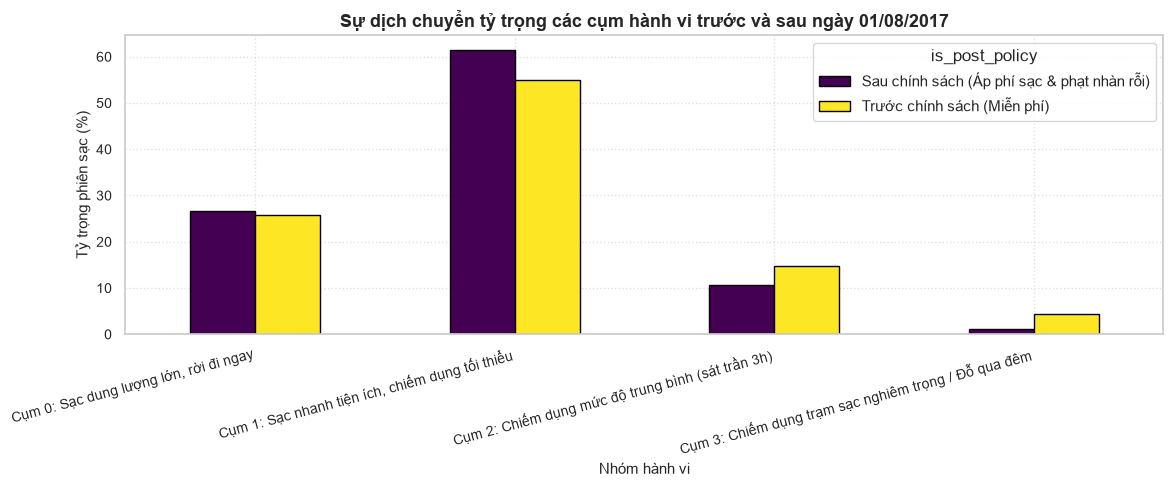

In [8]:
valid['is_post_policy'] = valid['start_datetime_utc'] >= '2017-08-01'
policy_shift = pd.crosstab(
    valid['cluster_label'], 
    valid['is_post_policy'].map({False: 'Trước chính sách (Miễn phí)', True: 'Sau chính sách (Áp phí sạc & phạt nhàn rỗi)'}), 
    normalize='columns'
) * 100

policy_shift['Chênh lệch (%)'] = policy_shift.iloc[:, 1] - policy_shift.iloc[:, 0]
print("=== SỰ DỊCH CHUYỂN CƠ CẤU HÀNH VI TRƯỚC VÀ SAU CHÍNH SÁCH GIÁ ===")
display(policy_shift.round(2))

# Trực quan hóa sự dịch chuyển
plt.figure(figsize=(10, 5))
policy_shift.iloc[:, :2].plot(kind='bar', figsize=(12, 5), colormap='viridis', edgecolor='black')
plt.title('Sự dịch chuyển tỷ trọng các cụm hành vi trước và sau ngày 01/08/2017', fontweight='bold')
plt.xlabel('Nhóm hành vi')
plt.ylabel('Tỷ trọng phiên sạc (%)')
plt.xticks(rotation=15, ha='right')
plt.grid(True, linestyle=':', alpha=0.6)
plt.tight_layout()
plt.show()